In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Kaggle working directory:", os.listdir("/kaggle/working"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Kaggle working directory: ['.virtual_documents']


In [3]:
!pip install -q huggingface_hub

In [4]:
import huggingface_hub
print("Hugging Face Hub version:", huggingface_hub.__version__)

Hugging Face Hub version: 1.33.0


In [5]:
from huggingface_hub import hf_hub_download

repo_id = "mohanty/PlantVillage"

train_file = hf_hub_download(
    repo_id=repo_id,
    filename="splits/color_train.txt",
    repo_type="dataset"
)

test_file = hf_hub_download(
    repo_id=repo_id,
    filename="splits/color_test.txt",
    repo_type="dataset"
)

zip_path = hf_hub_download(
    repo_id=repo_id,
    filename="data.zip",
    repo_type="dataset"
)

print("Training split:", train_file)
print("Testing split:", test_file)
print("Dataset archive:", zip_path)

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Training split: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/splits/color_train.txt
Testing split: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/splits/color_test.txt
Dataset archive: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip


In [6]:
import zipfile
import os

print("Archive size:",
      round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Total archive files:", len(z.namelist()))
    print("Corrupted file:", z.testzip())

Archive size: 2.03 GB
Total archive files: 163034
Corrupted file: None


In [7]:
import os
import zipfile

extract_dir = "/kaggle/working/PlantVillage"

with zipfile.ZipFile(zip_path, "r") as z:
    color_files = [
        name for name in z.namelist()
        if name.startswith("raw/color/")
    ]

    print("Color images found:", len(color_files))

    z.extractall(
        path=extract_dir,
        members=color_files
    )

print("Extraction completed!")
print("Dataset folder:", extract_dir)

Color images found: 54344
Extraction completed!
Dataset folder: /kaggle/working/PlantVillage


In [8]:
with open(train_file, "r") as f:
    train_paths = [line.strip() for line in f if line.strip()]

with open(test_file, "r") as f:
    test_paths = [line.strip() for line in f if line.strip()]

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))
print("Total split images:", len(train_paths) + len(test_paths))
print("Extracted color files:", len(color_files))

Training images: 43596
Testing images: 10709
Total split images: 54305
Extracted color files: 54344


In [9]:
import os

missing_train = [
    p for p in train_paths
    if not os.path.exists(os.path.join(extract_dir, p))
]

missing_test = [
    p for p in test_paths
    if not os.path.exists(os.path.join(extract_dir, p))
]

print("Missing training images:", len(missing_train))
print("Missing testing images:", len(missing_test))

Missing training images: 0
Missing testing images: 0


In [10]:
import os

class_names = sorted([
    folder for folder in os.listdir(
        os.path.join(extract_dir, "raw/color")
    )
    if os.path.isdir(
        os.path.join(extract_dir, "raw/color", folder)
    )
])

print("Total classes:", len(class_names))

print("\nClass names:")
for i, name in enumerate(class_names):
    print(i, ":", name)

Total classes: 38

Class names:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___Powdery_mildew
6 : Cherry_(including_sour)___healthy
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___Northern_Leaf_Blight
10 : Corn_(maize)___healthy
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 : Grape___healthy
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___Late_blight
22 : Potato___healthy
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___Leaf_scorch
27 : Strawberry___healthy
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___

In [11]:
from collections import Counter

train_labels = [
    path.split("/")[2] for path in train_paths
]

test_labels = [
    path.split("/")[2] for path in test_paths
]

train_counts = Counter(train_labels)
test_counts = Counter(test_labels)

print("Training class distribution:\n")

for class_name in class_names:
    print(f"{class_name}: {train_counts[class_name]}")

print("\nTotal training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))
print("Training classes:", len(train_counts))
print("Testing classes:", len(test_counts))

Training class distribution:

Apple___Apple_scab: 503
Apple___Black_rot: 475
Apple___Cedar_apple_rust: 223
Apple___healthy: 1359
Blueberry___healthy: 1178
Cherry_(including_sour)___Powdery_mildew: 833
Cherry_(including_sour)___healthy: 731
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 406
Corn_(maize)___Common_rust_: 975
Corn_(maize)___Northern_Leaf_Blight: 765
Corn_(maize)___healthy: 912
Grape___Black_rot: 1012
Grape___Esca_(Black_Measles): 1099
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 872
Grape___healthy: 323
Orange___Haunglongbing_(Citrus_greening): 4527
Peach___Bacterial_spot: 1755
Peach___healthy: 289
Pepper,_bell___Bacterial_spot: 831
Pepper,_bell___healthy: 1195
Potato___Early_blight: 836
Potato___Late_blight: 788
Potato___healthy: 120
Raspberry___healthy: 209
Soybean___healthy: 4117
Squash___Powdery_mildew: 1457
Strawberry___Leaf_scorch: 909
Strawberry___healthy: 376
Tomato___Bacterial_spot: 1691
Tomato___Early_blight: 785
Tomato___Late_blight: 1534
Tomato___Leaf_Mold:

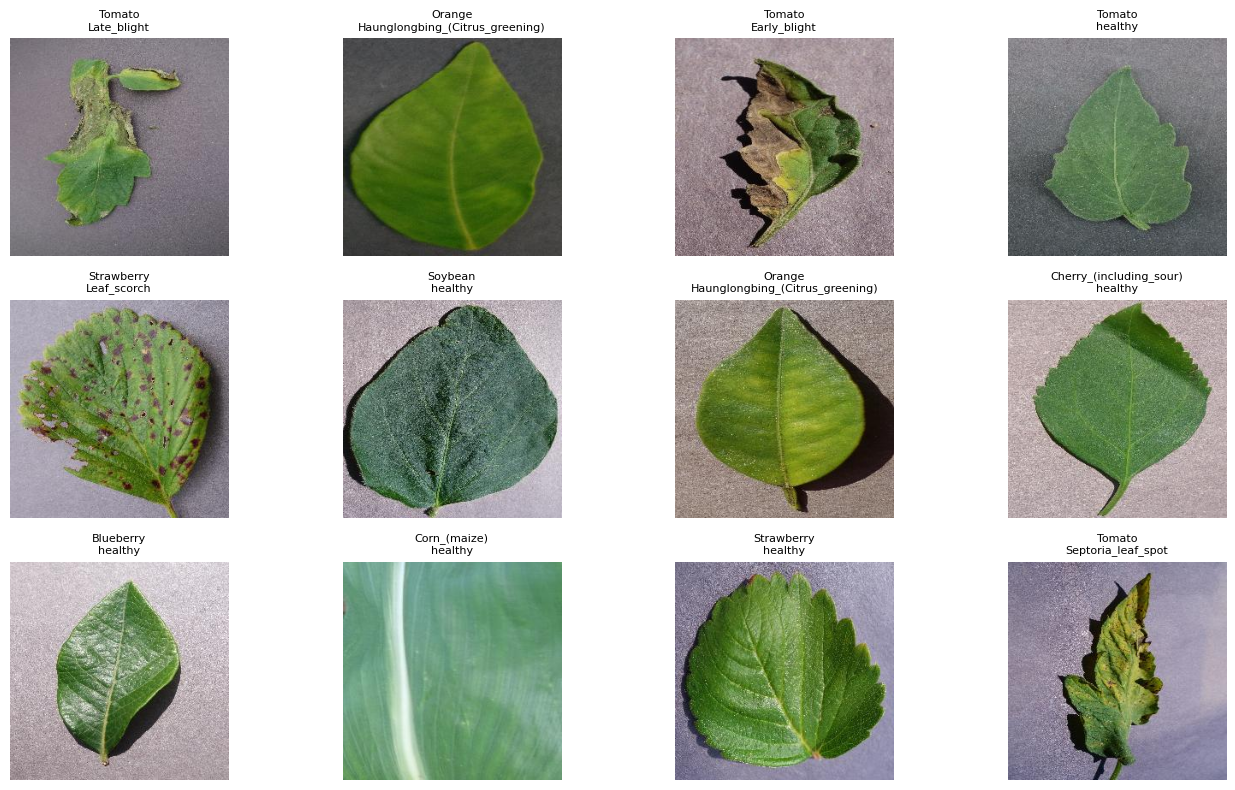

In [12]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(14, 8))

sample_paths = random.sample(train_paths, 12)

for i, path in enumerate(sample_paths):
    image_path = os.path.join(extract_dir, path)
    image = Image.open(image_path).convert("RGB")

    label = path.split("/")[2]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(label.replace("___", "\n"), fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

train_image_paths = [
    os.path.join(extract_dir, path)
    for path in train_paths
]

test_image_paths = [
    os.path.join(extract_dir, path)
    for path in test_paths
]

train_y = np.array([
    class_to_index[path.split("/")[2]]
    for path in train_paths
])

test_y = np.array([
    class_to_index[path.split("/")[2]]
    for path in test_paths
])

print("Training images:", len(train_image_paths))
print("Testing images:", len(test_image_paths))
print("Number of classes:", len(class_to_index))
print("First 10 training labels:", train_y[:10])
print("First 10 test labels:", test_y[:10])

Training images: 43596
Testing images: 10709
Number of classes: 38
First 10 training labels: [23 23 23 23 23 23 23 23 23 23]
First 10 test labels: [23 23 23 23 23 23 23 23 23 23]


In [14]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    return image, label

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_image_paths, train_y)
)

train_ds = (
    train_ds
    .shuffle(5000, seed=SEED)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_image_paths, test_y)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [15]:
from sklearn.model_selection import train_test_split

train_paths_new, val_paths, train_labels_new, val_labels = train_test_split(
    train_image_paths,
    train_y,
    test_size=0.10,
    random_state=SEED,
    stratify=train_y
)

def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(5000, seed=SEED)

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = create_dataset(train_paths_new, train_labels_new, training=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_image_paths, test_y)

print("Training images:", len(train_paths_new))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_image_paths))

Training images: 39236
Validation images: 4360
Testing images: 10709


In [16]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0
First 10 labels: [15 10 32 10 23 16 24 28  6 25]


In [17]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!
Total layers: 154
Trainable: False


In [18]:
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 preprocessing: [0, 255] -> [-1, 1]
x = layers.Rescaling(scale=1./127.5, offset=-1)(inputs)

# Feature extraction
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(38, activation="softmax")(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: Sparse Categorical Crossentropy")

Model compiled successfully!
Optimizer: Adam
Learning rate: 0.001
Loss: Sparse Categorical Crossentropy


In [20]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint = ModelCheckpoint(
    "/kaggle/working/best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stopping, reduce_lr]

print("Training callbacks configured successfully!")


Training callbacks configured successfully!


In [21]:
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7497 - loss: 0.9758
Epoch 1: val_loss improved from None to 0.20657, saving model to /kaggle/working/best_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/best_mobilenetv2.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 60s 38ms/step - accuracy: 0.8594 - loss: 0.5130 - val_accuracy: 0.9408 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 2/15
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9315 - loss: 0.2223
Epoch 2: val_loss improved from 0.20657 to 0.16580, saving model to /kaggle/working/best_mobilenetv2.keras

Epoch 2: finished saving model to /kaggle/working/best_mobilenetv2.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.9341 - loss: 0.2111 - val_accuracy: 0.9498 - val_loss: 0.1658 - learning_rate: 0.0010
Epoch 3/15
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9430 - loss: 0.1762
Epoch 3: val_loss improved from 0.16580 to 0.14666, saving model to /kaggle/working/

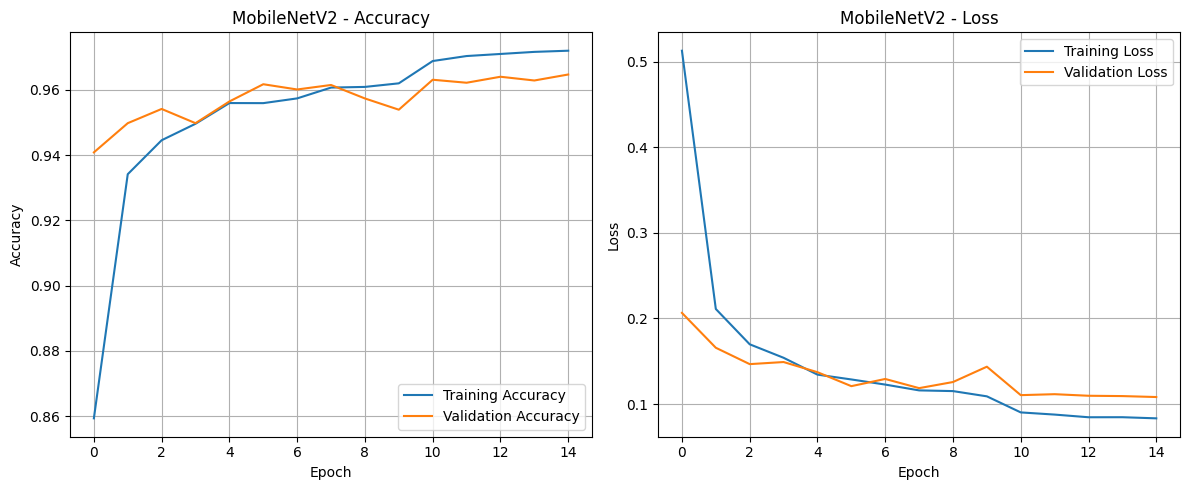

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [23]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

335/335 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.9589 - loss: 0.1315
Test Loss: 0.1315
Test Accuracy: 95.89 %


In [24]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

y_true = test_y

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro Precision:", precision_score(y_true, y_pred, average="macro"))
print("Macro Recall:", recall_score(y_true, y_pred, average="macro"))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

335/335 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step
Accuracy: 0.9589130637781306
Macro Precision: 0.9524996382178836
Macro Recall: 0.9420653622386151
Macro F1: 0.9464927307314603

Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9316    0.8583    0.8934       127
                                 Apple___Black_rot     1.0000    0.9863    0.9931       146
                          Apple___Cedar_apple_rust     0.9796    0.9231    0.9505        52
                                   Apple___healthy     0.9592    0.9860    0.9724       286
                               Blueberry___healthy     0.9908    0.9969    0.9938       324
          Cherry_(including_sour)___Powdery_mildew     0.9604    0.9954    0.9776       219
                 Cherry_(including_sour)___healthy     0.9840    1.0000    0.9919       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8017    0.8

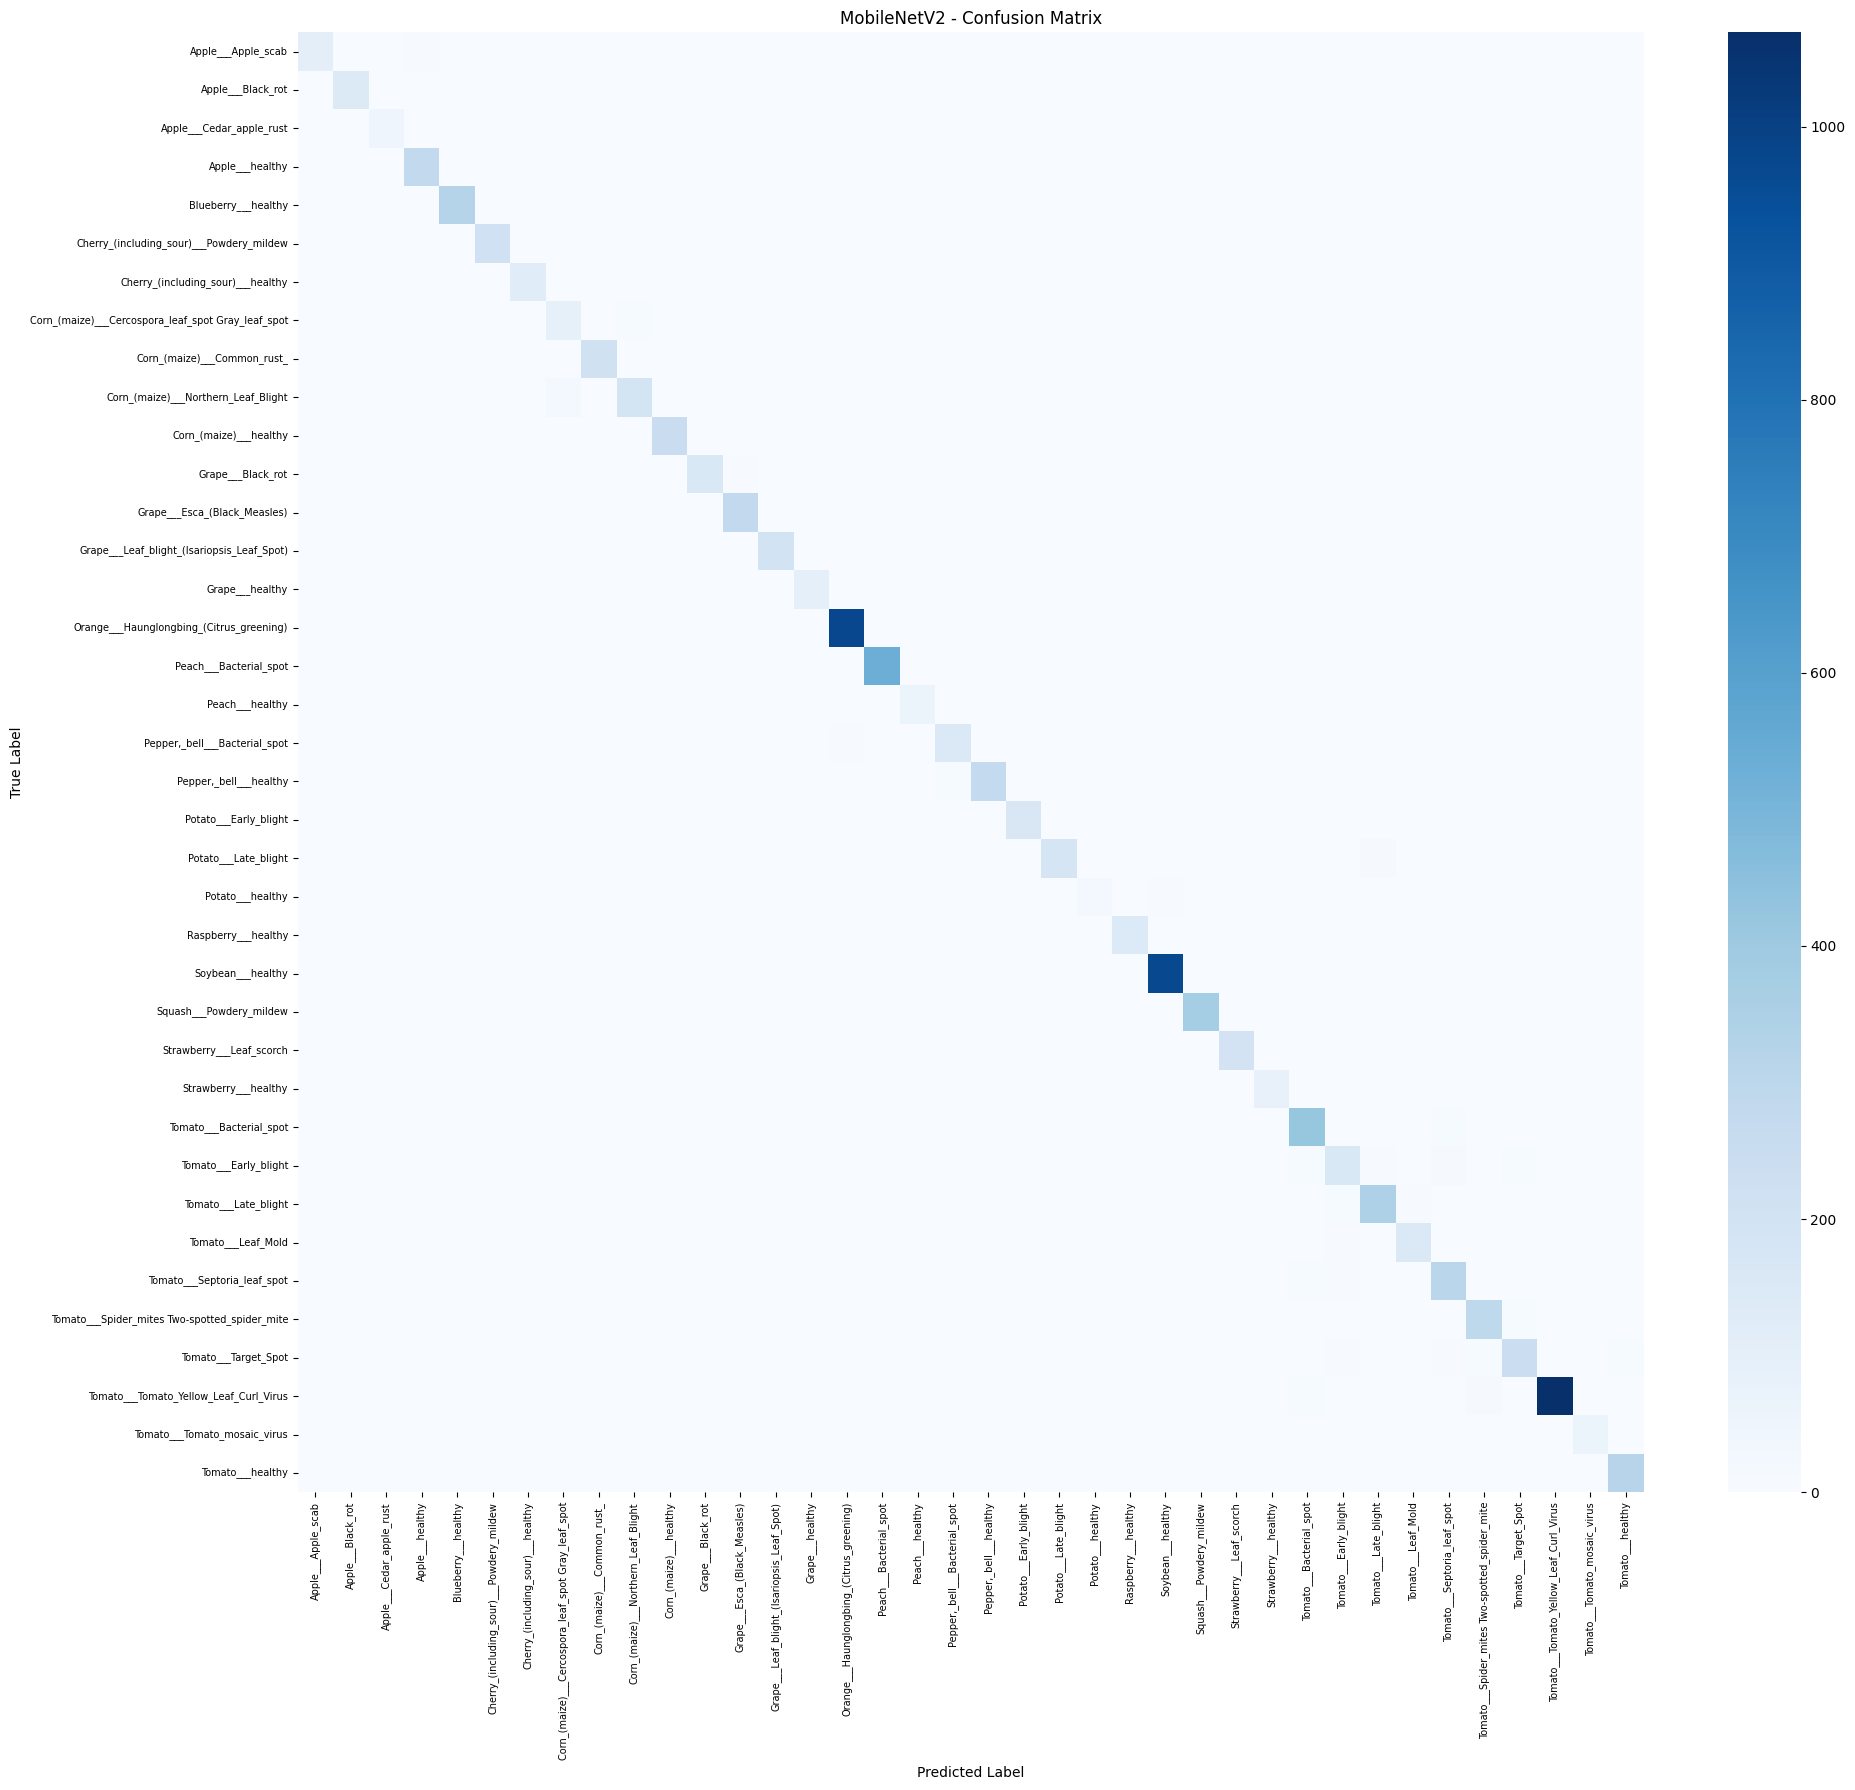

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.show()


In [26]:
import numpy as np
import pandas as pd

cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

confused_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm_without_diagonal[i, j] > 0:
            confused_pairs.append({
                "Actual Disease": class_names[i],
                "Predicted Disease": class_names[j],
                "Wrong Predictions": cm_without_diagonal[i, j]
            })

confused_df = pd.DataFrame(confused_pairs)

confused_df = confused_df.sort_values(
    "Wrong Predictions",
    ascending=False
)

print(confused_df.head(10).to_string(index=False))

                                    Actual Disease                                  Predicted Disease  Wrong Predictions
               Corn_(maize)___Northern_Leaf_Blight Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot                 23
                              Potato___Late_blight                               Tomato___Late_blight                 16
                             Tomato___Early_blight                        Tomato___Septoria_leaf_spot                 16
            Tomato___Tomato_Yellow_Leaf_Curl_Virus      Tomato___Spider_mites Two-spotted_spider_mite                 14
                              Tomato___Target_Spot      Tomato___Spider_mites Two-spotted_spider_mite                 12
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot                Corn_(maize)___Northern_Leaf_Blight                 12
            Tomato___Tomato_Yellow_Leaf_Curl_Virus                            Tomato___Bacterial_spot                 11
     Tomato___Spider_mites Two-s

In [27]:
baseline_results = {
    "Model": "MobileNetV2",
    "Clean_Test_Accuracy": accuracy_score(y_true, y_pred),
    "Macro_Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro_Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro_F1": f1_score(y_true, y_pred, average="macro")
}

baseline_df = pd.DataFrame([baseline_results])

baseline_df.to_csv(
    "/kaggle/working/mobilenetv2_baseline_results.csv",
    index=False
)

print(baseline_df.to_string(index=False))
print("\nBaseline results saved successfully!")

      Model  Clean_Test_Accuracy  Macro_Precision  Macro_Recall  Macro_F1
MobileNetV2             0.958913           0.9525      0.942065  0.946493

Baseline results saved successfully!


In [28]:
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras import layers, Model

base_v3 = MobileNetV3Small(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_v3.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV3Small includes its own preprocessing
x = base_v3(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(38, activation="softmax")(x)

model_v3 = Model(inputs, outputs, name="MobileNetV3Small")

model_v3.summary()

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV3Small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        21,926 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961,046 (3.67 MB)

 Trainable params: 21,926 (85.65 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [29]:
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV3Small compiled successfully!")

MobileNetV3Small compiled successfully!


In [30]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint_v3 = ModelCheckpoint(
    "/kaggle/working/best_mobilenetv3small.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_v3 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v3 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks_v3 = [
    checkpoint_v3,
    early_stopping_v3,
    reduce_lr_v3
]

print("MobileNetV3Small callbacks configured!")

MobileNetV3Small callbacks configured!


In [31]:
EPOCHS = 15

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_v3
)


Epoch 1/15
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6573 - loss: 1.3469
Epoch 1: val_loss improved from None to 0.25879, saving model to /kaggle/working/best_mobilenetv3small.keras

Epoch 1: finished saving model to /kaggle/working/best_mobilenetv3small.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 50s 29ms/step - accuracy: 0.8069 - loss: 0.7483 - val_accuracy: 0.9335 - val_loss: 0.2588 - learning_rate: 0.0010
Epoch 2/15
1224/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9187 - loss: 0.2907
Epoch 2: val_loss improved from 0.25879 to 0.17469, saving model to /kaggle/working/best_mobilenetv3small.keras

Epoch 2: finished saving model to /kaggle/working/best_mobilenetv3small.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9238 - loss: 0.2704 - val_accuracy: 0.9541 - val_loss: 0.1747 - learning_rate: 0.0010
Epoch 3/15
1225/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9404 - loss: 0.2062
Epoch 3: val_loss improved from 0.17469 to 0.14036, saving model

In [32]:
test_loss_v3, test_accuracy_v3 = model_v3.evaluate(test_ds)

print("MobileNetV3Small Test Results")
print("Test Loss:", test_loss_v3)
print("Test Accuracy:", test_accuracy_v3 * 100, "%")

335/335 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.9688 - loss: 0.0988
MobileNetV3Small Test Results
Test Loss: 0.09876436740159988
Test Accuracy: 96.88112735748291 %


In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob_v3 = model_v3.predict(test_ds)
y_pred_v3 = np.argmax(y_prob_v3, axis=1)

print("MobileNetV3Small Evaluation")
print("Accuracy:", accuracy_score(y_true, y_pred_v3))
print("Macro Precision:", precision_score(y_true, y_pred_v3, average="macro"))
print("Macro Recall:", recall_score(y_true, y_pred_v3, average="macro"))
print("Macro F1:", f1_score(y_true, y_pred_v3, average="macro"))

335/335 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step
MobileNetV3Small Evaluation
Accuracy: 0.9688112802315809
Macro Precision: 0.9678233682691688
Macro Recall: 0.9573386163494492
Macro F1: 0.9613632566418003


In [34]:
import pandas as pd

v3_results = pd.DataFrame([{
    "Model": "MobileNetV3Small",
    "Test Accuracy": accuracy_score(y_true, y_pred_v3),
    "Macro Precision": precision_score(y_true, y_pred_v3, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred_v3, average="macro"),
    "Macro F1": f1_score(y_true, y_pred_v3, average="macro"),
    "Test Loss": test_loss_v3,
    "Parameters": model_v3.count_params()
}])

v3_results.to_csv(
    "/kaggle/working/mobilenetv3small_results.csv",
    index=False
)

print(v3_results)
print("Results saved successfully!")

              Model  Test Accuracy  Macro Precision  Macro Recall  Macro F1  \
0  MobileNetV3Small       0.968811         0.967823      0.957339  0.961363   

   Test Loss  Parameters  
0   0.098764      961046  
Results saved successfully!


In [35]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras import layers, Model

base_eff = EfficientNetV2B0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_eff.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# EfficientNetV2B0 includes preprocessing by default
x = base_eff(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(38, activation="softmax")(x)

model_eff = Model(inputs, outputs, name="EfficientNetV2B0")

model_eff.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetV2B0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,967,990 (22.77 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [36]:
model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetV2B0 compiled successfully!")

EfficientNetV2B0 compiled successfully!


In [37]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint_eff = ModelCheckpoint(
    "/kaggle/working/best_efficientnetv2b0.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_eff = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_eff = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks_eff = [
    checkpoint_eff,
    early_stopping_eff,
    reduce_lr_eff
]

print("EfficientNetV2B0 callbacks configured!")

EfficientNetV2B0 callbacks configured!


In [38]:
history_eff = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_eff
)

Epoch 1/15
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7264 - loss: 1.1420
Epoch 1: val_loss improved from None to 0.21321, saving model to /kaggle/working/best_efficientnetv2b0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetv2b0.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 96s 58ms/step - accuracy: 0.8532 - loss: 0.6204 - val_accuracy: 0.9482 - val_loss: 0.2132 - learning_rate: 0.0010
Epoch 2/15
1225/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9371 - loss: 0.2395
Epoch 2: val_loss improved from 0.21321 to 0.14459, saving model to /kaggle/working/best_efficientnetv2b0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetv2b0.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 48s 39ms/step - accuracy: 0.9412 - loss: 0.2183 - val_accuracy: 0.9606 - val_loss: 0.1446 - learning_rate: 0.0010
Epoch 3/15
1225/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9515 - loss: 0.1723
Epoch 3: val_loss improved from 0.14459 to 0.11072, saving model

In [39]:
test_loss_eff, test_accuracy_eff = model_eff.evaluate(test_ds)

print("EfficientNetV2B0 Test Results")
print("Test Loss:", test_loss_eff)
print("Test Accuracy:", test_accuracy_eff * 100, "%")

335/335 ━━━━━━━━━━━━━━━━━━━━ 16s 49ms/step - accuracy: 0.9800 - loss: 0.0685
EfficientNetV2B0 Test Results
Test Loss: 0.06849972903728485
Test Accuracy: 98.0016827583313 %


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob_eff = model_eff.predict(test_ds)
y_pred_eff = np.argmax(y_prob_eff, axis=1)



335/335 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step


In [41]:
y_true = test_y

print("EfficientNetV2B0 Evaluation")
print("Accuracy:", accuracy_score(y_true, y_pred_eff))
print("Macro Precision:", precision_score(y_true, y_pred_eff, average="macro"))
print("Macro Recall:", recall_score(y_true, y_pred_eff, average="macro"))
print("Macro F1:", f1_score(y_true, y_pred_eff, average="macro"))

EfficientNetV2B0 Evaluation
Accuracy: 0.9800168082920908
Macro Precision: 0.9774565790184128
Macro Recall: 0.9700042683143187
Macro F1: 0.9733073057911337


In [42]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Accuracy": 0.958913,
        "Precision": 0.952500,
        "Recall": 0.942065,
        "Macro F1": 0.946493,
        "Test Loss": 0.1315,
        "Parameters": 2306662
    },
    {
        "Model": "MobileNetV3Small",
        "Accuracy": 0.968811,
        "Precision": 0.967823,
        "Recall": 0.957339,
        "Macro F1": 0.961363,
        "Test Loss": 0.098764,
        "Parameters": 961046
    },
    {
        "Model": "EfficientNetV2B0",
        "Accuracy": 0.976468,
        "Precision": 0.974114,
        "Recall": 0.965939,
        "Macro F1": 0.969281,
        "Test Loss": 0.075636,
        "Parameters": 5967990
    }
])

comparison.to_csv(
    "/kaggle/working/baseline_model_comparison.csv",
    index=False
)

print(comparison)
print("\nCombined results saved successfully!")

              Model  Accuracy  Precision    Recall  Macro F1  Test Loss  \
0       MobileNetV2  0.958913   0.952500  0.942065  0.946493   0.131500   
1  MobileNetV3Small  0.968811   0.967823  0.957339  0.961363   0.098764   
2  EfficientNetV2B0  0.976468   0.974114  0.965939  0.969281   0.075636   

   Parameters  
0     2306662  
1      961046  
2     5967990  

Combined results saved successfully!


In [43]:
import cv2
import numpy as np

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Corruption testing environment ready!")

OpenCV version: 4.14.0
NumPy version: 2.1.3
Corruption testing environment ready!


In [44]:
def apply_blur(image, severity):
    blur_levels = {
        1: 3,
        2: 5,
        3: 7
    }

    kernel_size = blur_levels[severity]

    blurred = cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        0
    )

    return blurred

print("Gaussian Blur function created!")

Gaussian Blur function created!


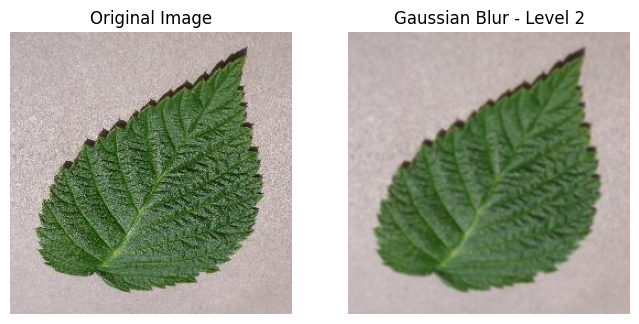

In [45]:
sample_img = cv2.imread(test_image_paths[0])
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

sample_blur = apply_blur(sample_img, 2)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_blur)
plt.title("Gaussian Blur - Level 2")
plt.axis("off")

plt.show()

In [46]:
def apply_gaussian_noise(image, severity):
    noise_levels = {
        1: 10,
        2: 20,
        3: 30
    }

    noise = np.random.normal(
        0,
        noise_levels[severity],
        image.shape
    )

    noisy_image = image.astype(np.float32) + noise
    noisy_image = np.clip(noisy_image, 0, 255)

    return noisy_image.astype(np.uint8)

print("Gaussian Noise function created!")

Gaussian Noise function created!


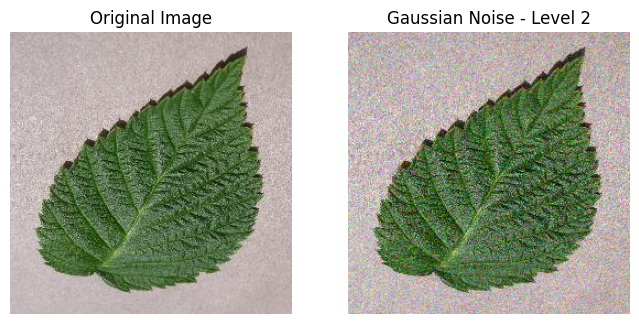

In [47]:
sample_noise = apply_gaussian_noise(sample_img, 2)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_noise)
plt.title("Gaussian Noise - Level 2")
plt.axis("off")

plt.show()

In [48]:
def apply_brightness_contrast(image, severity):
    settings = {
        1: (1.0, 30),
        2: (1.0, 60),
        3: (0.5, 0)
    }

    alpha, beta = settings[severity]

    adjusted = cv2.convertScaleAbs(
        image,
        alpha=alpha,
        beta=beta
    )

    return adjusted

print("Brightness and Contrast function created!")

Brightness and Contrast function created!


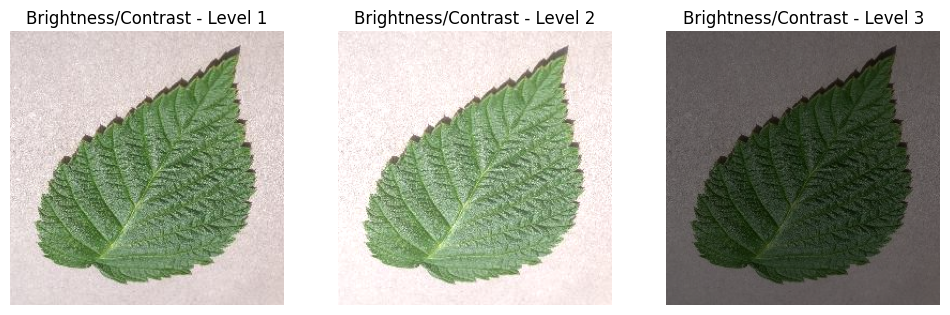

In [49]:
plt.figure(figsize=(12, 4))

for level in range(1, 4):
    adjusted = apply_brightness_contrast(sample_img, level)

    plt.subplot(1, 3, level)
    plt.imshow(adjusted)
    plt.title(f"Brightness/Contrast - Level {level}")
    plt.axis("off")

plt.show()

In [50]:
def apply_jpeg_compression(image, severity):
    quality_levels = {
        1: 70,
        2: 40,
        3: 15
    }

    quality = quality_levels[severity]

    success, encoded = cv2.imencode(
        ".jpg",
        image,
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )

    compressed = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    compressed = cv2.cvtColor(compressed, cv2.COLOR_BGR2RGB)

    return compressed

print("JPEG Compression function created!")


JPEG Compression function created!


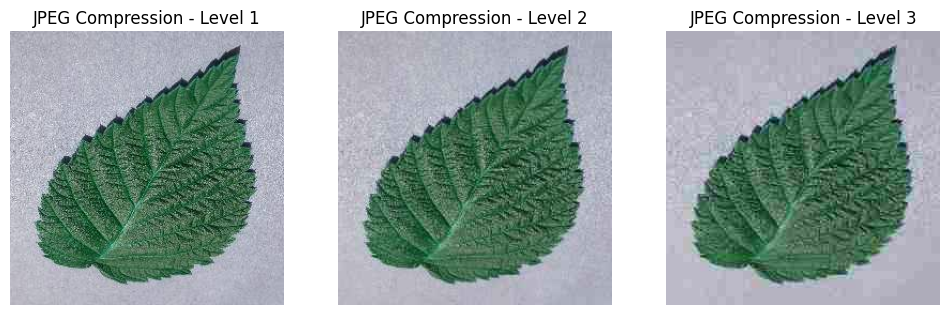

In [51]:
plt.figure(figsize=(12, 4))

for level in range(1, 4):
    compressed = apply_jpeg_compression(sample_img, level)

    plt.subplot(1, 3, level)
    plt.imshow(compressed)
    plt.title(f"JPEG Compression - Level {level}")
    plt.axis("off")

plt.show()

In [52]:
def apply_corruption(image, corruption, severity):
    if corruption == "blur":
        return apply_blur(image, severity)

    elif corruption == "noise":
        return apply_gaussian_noise(image, severity)

    elif corruption == "brightness":
        return apply_brightness_contrast(image, severity)

    elif corruption == "jpeg":
        return apply_jpeg_compression(image, severity)

    else:
        raise ValueError("Unknown corruption type")


print("Common corruption function created!")

Common corruption function created!


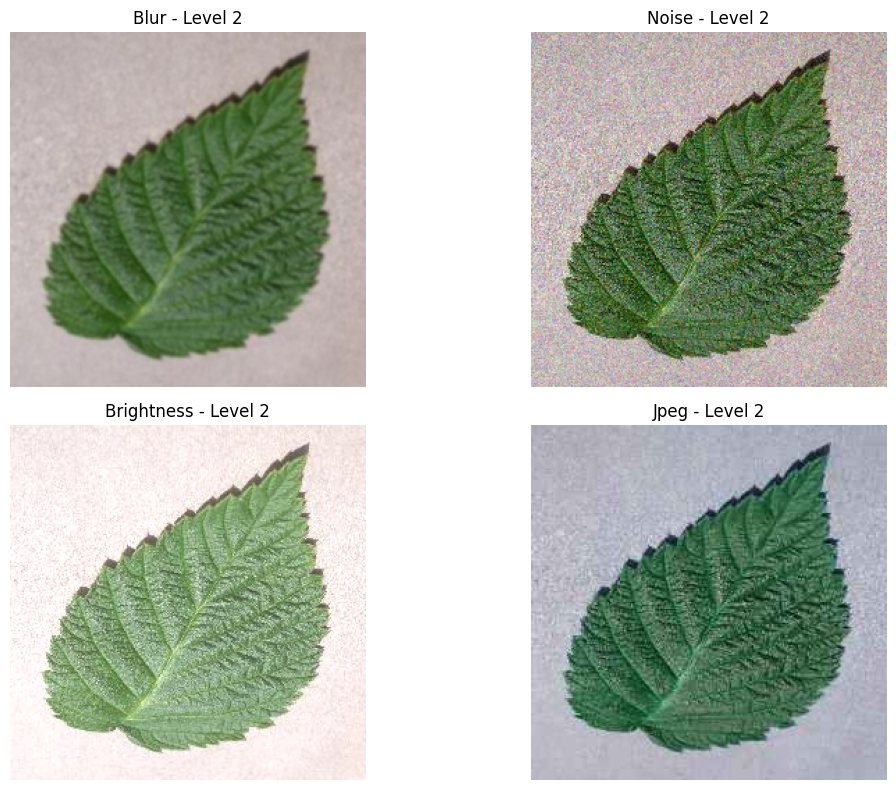

In [53]:
corruption_types = ["blur", "noise", "brightness", "jpeg"]

plt.figure(figsize=(12, 8))

for i, corruption in enumerate(corruption_types):
    corrupted = apply_corruption(sample_img, corruption, 2)

    plt.subplot(2, 2, i + 1)
    plt.imshow(corrupted)
    plt.title(f"{corruption.title()} - Level 2")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [54]:
def apply_gaussian_noise(image, severity, seed=42):
    noise_levels = {
        1: 10,
        2: 20,
        3: 30
    }

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        0,
        noise_levels[severity],
        image.shape
    )

    noisy_image = image.astype(np.float32) + noise
    noisy_image = np.clip(noisy_image, 0, 255)

    return noisy_image.astype(np.uint8)


print("Deterministic Gaussian Noise function created!")

Deterministic Gaussian Noise function created!


In [55]:
noise_test_1 = apply_gaussian_noise(sample_img, 2, seed=42)
noise_test_2 = apply_gaussian_noise(sample_img, 2, seed=42)

print("Identical results:", np.array_equal(noise_test_1, noise_test_2))

Identical results: True


In [56]:
def apply_corruption(image, corruption, severity, seed=42):
    if corruption == "blur":
        return apply_blur(image, severity)

    elif corruption == "noise":
        return apply_gaussian_noise(image, severity, seed=seed)

    elif corruption == "brightness":
        return apply_brightness_contrast(image, severity)

    elif corruption == "jpeg":
        return apply_jpeg_compression(image, severity)

    else:
        raise ValueError("Unknown corruption type")


print("Updated corruption function ready!")

Updated corruption function ready!


In [57]:
def load_corrupted_image(path, corruption, severity, seed=42):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    image = image.numpy().astype(np.uint8)

    image = apply_corruption(
        image,
        corruption,
        severity,
        seed=seed
    )

    return image.astype(np.float32)


print("Corrupted image loader created!")

Corrupted image loader created!


Image shape: (224, 224, 3)
Data type: float32
Minimum pixel: 15.0
Maximum pixel: 216.0


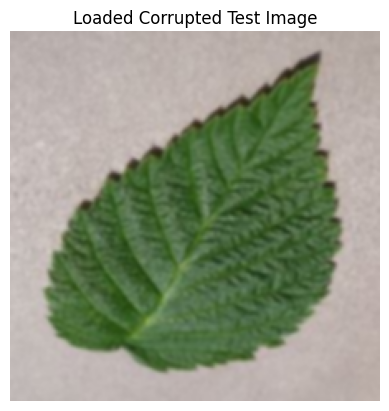

In [58]:
test_sample = load_corrupted_image(
    test_image_paths[0],
    corruption="blur",
    severity=2
)

print("Image shape:", test_sample.shape)
print("Data type:", test_sample.dtype)
print("Minimum pixel:", test_sample.min())
print("Maximum pixel:", test_sample.max())

plt.imshow(test_sample.astype(np.uint8))
plt.title("Loaded Corrupted Test Image")
plt.axis("off")
plt.show()

In [59]:
def corrupted_test_generator(corruption, severity):
    for idx, (path, label) in enumerate(zip(test_image_paths, test_y)):
        image = load_corrupted_image(
            path,
            corruption,
            severity,
            seed=SEED + idx
        )

        yield image, np.int32(label)

print("Corrupted test generator created!")

Corrupted test generator created!


In [60]:
test_generator_ds = tf.data.Dataset.from_generator(
    lambda: corrupted_test_generator("blur", 2),
    output_signature=(
        tf.TensorSpec(shape=(224, 224, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
)

small_batch = next(iter(test_generator_ds.batch(8)))

batch_images, batch_labels = small_batch

print("Batch image shape:", batch_images.shape)
print("Batch label shape:", batch_labels.shape)
print("Image data type:", batch_images.dtype)
print("Label data type:", batch_labels.dtype)

Batch image shape: (8, 224, 224, 3)
Batch label shape: (8,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>


In [61]:
small_predictions = model_eff.predict(
    batch_images,
    verbose=0
)

print("Prediction shape:", small_predictions.shape)
print("Predicted classes:", np.argmax(small_predictions, axis=1))
print("Actual classes:", batch_labels.numpy())

Prediction shape: (8, 38)
Predicted classes: [23 23 23 23 23 23 23 23]
Actual classes: [23 23 23 23 23 23 23 23]


In [62]:
from tensorflow.keras.models import load_model

model_v2 = load_model(
    "/kaggle/working/best_mobilenetv2.keras"
)

model_v3 = load_model(
    "/kaggle/working/best_mobilenetv3small.keras"
)

model_eff = load_model(
    "/kaggle/working/best_efficientnetv2b0.keras"
)

print("All three trained models loaded successfully!")

All three trained models loaded successfully!


In [63]:
models = {
    "MobileNetV2": model_v2,
    "MobileNetV3Small": model_v3,
    "EfficientNetV2B0": model_eff
}

for name, loaded_model in models.items():
    print(f"{name}: {loaded_model.count_params():,} parameters")

MobileNetV2: 2,306,662 parameters
MobileNetV3Small: 961,046 parameters
EfficientNetV2B0: 5,967,990 parameters


In [64]:
pred_v2 = np.argmax(
    model_v2.predict(batch_images, verbose=0), axis=1
)

pred_v3 = np.argmax(
    model_v3.predict(batch_images, verbose=0), axis=1
)

pred_eff = np.argmax(
    model_eff.predict(batch_images, verbose=0), axis=1
)

actual = batch_labels.numpy()

print("MobileNetV2 correct:", np.sum(pred_v2 == actual), "/ 8")
print("MobileNetV3Small correct:", np.sum(pred_v3 == actual), "/ 8")
print("EfficientNetV2B0 correct:", np.sum(pred_eff == actual), "/ 8")

MobileNetV2 correct: 7 / 8
MobileNetV3Small correct: 8 / 8
EfficientNetV2B0 correct: 8 / 8


In [65]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate_corruption(model, corruption, severity):
    dataset = tf.data.Dataset.from_generator(
        lambda: corrupted_test_generator(corruption, severity),
        output_signature=(
            tf.TensorSpec((224, 224, 3), tf.float32),
            tf.TensorSpec((), tf.int32)
        )
    ).batch(BATCH_SIZE).prefetch(AUTOTUNE)

    predictions = model.predict(dataset, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    return {
        "accuracy": accuracy_score(test_y, y_pred),
        "macro_f1": f1_score(test_y, y_pred, average="macro")
    }

print("Corruption evaluation function created!")

Corruption evaluation function created!


In [66]:
models = {
    "MobileNetV2": model_v2,
    "MobileNetV3Small": model_v3,
    "EfficientNetV2B0": model_eff
}

for name, current_model in models.items():
    scores = evaluate_corruption(current_model, "blur", 2)
    print(
        name,
        "| Accuracy:", round(scores["accuracy"] * 100, 2), "%",
        "| Macro F1:", round(scores["macro_f1"] * 100, 2), "%"
    )

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


MobileNetV2 | Accuracy: 86.24 % | Macro F1: 84.02 %


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


MobileNetV3Small | Accuracy: 90.95 % | Macro F1: 88.71 %
EfficientNetV2B0 | Accuracy: 90.88 % | Macro F1: 89.13 %


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [67]:
def evaluate_corruption(model, corruption, severity):
    dataset = tf.data.Dataset.from_generator(
        lambda: corrupted_test_generator(corruption, severity),
        output_signature=(
            tf.TensorSpec((224, 224, 3), tf.float32),
            tf.TensorSpec((), tf.int32)
        )
    ).batch(BATCH_SIZE)

    all_predictions = []
    all_labels = []

    for images, labels in dataset:
        outputs = model(images, training=False)
        predictions = tf.argmax(outputs, axis=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

    return {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels, all_predictions, average="macro"
        ),
        "samples": len(all_labels)
    }

print("Evaluation function updated!")

Evaluation function updated!


In [68]:
check = evaluate_corruption(model_v2, "blur", 2)

print("Accuracy:", round(check["accuracy"] * 100, 2), "%")
print("Macro F1:", round(check["macro_f1"] * 100, 2), "%")
print("Images evaluated:", check["samples"])
print("Expected images:", len(test_y))

Accuracy: 86.24 %
Macro F1: 84.02 %
Images evaluated: 10709
Expected images: 10709


In [69]:
corruptions = ["blur", "noise", "brightness", "jpeg"]
severities = [1, 2, 3]

results = []

for corruption in corruptions:
    for severity in severities:
        print(f"\nTesting {corruption}, severity {severity}")

        for name, current_model in models.items():
            scores = evaluate_corruption(
                current_model, corruption, severity
            )

            results.append({
                "Model": name,
                "Corruption": corruption,
                "Severity": severity,
                "Accuracy": scores["accuracy"],
                "Macro_F1": scores["macro_f1"],
                "Samples": scores["samples"]
            })

            print(
                name,
                "| Accuracy:", round(scores["accuracy"] * 100, 2), "%",
                "| F1:", round(scores["macro_f1"] * 100, 2), "%"
            )

corruption_results = pd.DataFrame(results)

corruption_results.to_csv(
    "/kaggle/working/corruption_benchmark_results.csv",
    index=False
)

print("\nBenchmark completed!")
print("Total evaluations:", len(corruption_results))


Testing blur, severity 1
MobileNetV2 | Accuracy: 90.95 % | F1: 89.57 %
MobileNetV3Small | Accuracy: 94.06 % | F1: 92.63 %
EfficientNetV2B0 | Accuracy: 95.4 % | F1: 94.2 %

Testing blur, severity 2
MobileNetV2 | Accuracy: 86.24 % | F1: 84.02 %
MobileNetV3Small | Accuracy: 90.95 % | F1: 88.71 %
EfficientNetV2B0 | Accuracy: 90.88 % | F1: 89.13 %

Testing blur, severity 3
MobileNetV2 | Accuracy: 79.39 % | F1: 74.56 %
MobileNetV3Small | Accuracy: 82.34 % | F1: 79.14 %
EfficientNetV2B0 | Accuracy: 83.53 % | F1: 81.35 %

Testing noise, severity 1
MobileNetV2 | Accuracy: 87.8 % | F1: 85.53 %
MobileNetV3Small | Accuracy: 94.06 % | F1: 92.47 %
EfficientNetV2B0 | Accuracy: 95.03 % | F1: 93.39 %

Testing noise, severity 2
MobileNetV2 | Accuracy: 63.51 % | F1: 55.85 %
MobileNetV3Small | Accuracy: 87.88 % | F1: 84.47 %
EfficientNetV2B0 | Accuracy: 89.32 % | F1: 86.49 %

Testing noise, severity 3
MobileNetV2 | Accuracy: 39.5 % | F1: 30.45 %
MobileNetV3Small | Accuracy: 75.44 % | F1: 69.2 %
Efficient

In [70]:
import pandas as pd

corruption_results = pd.DataFrame(results)

corruption_results.to_csv(
    "/kaggle/working/corruption_benchmark_results.csv",
    index=False
)

print("Saved successfully!")
print("Total evaluations:", len(corruption_results))
print(corruption_results.head())

Saved successfully!
Total evaluations: 36
              Model Corruption  Severity  Accuracy  Macro_F1  Samples
0       MobileNetV2       blur         1  0.909515  0.895702    10709
1  MobileNetV3Small       blur         1  0.940611  0.926304    10709
2  EfficientNetV2B0       blur         1  0.953964  0.942007    10709
3       MobileNetV2       blur         2  0.862359  0.840153    10709
4  MobileNetV3Small       blur         2  0.909515  0.887114    10709


In [71]:
import os

files_to_check = [
    "/kaggle/working/best_mobilenetv3small.keras",
    "/kaggle/working/mobilenetv3small_results.csv",
    "/kaggle/working/corruption_benchmark_results.csv"
]

for file in files_to_check:
    print(os.path.basename(file), ":", os.path.exists(file))

best_mobilenetv3small.keras : True
mobilenetv3small_results.csv : True
corruption_benchmark_results.csv : True
